## Exploración de datos
### Tabla de pedidos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("archive/olist_orders_dataset.csv")
print(orders.shape)
print(orders.head())
orders.info()

(99441, 8)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00       

La tabla de pedidos tiene 99.441 filas y 8 columnas. Las columnas de fechas están guardadas como texto, así que habrá que convertirlas antes de poder restarlas. Además, faltan valores en tres de ellas: 160 en `order_approved_at`, 1.783 en `order_delivered_carrier_date` y 2.965 en `order_delivered_customer_date`.

In [2]:
print(orders["order_status"].value_counts())
print(orders.isna().sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


El estado más común es `delivered` (96.478 pedidos); el resto se reparte entre `shipped`, `canceled`, `unavailable`, `invoiced`, `processing`, `created` y `approved`.

In [3]:
sin_fecha = orders[orders["order_delivered_customer_date"].isna()]
print(sin_fecha["order_status"].value_counts())

entregados_sin_fecha = orders[(orders["order_status"] == "delivered") & (orders["order_delivered_customer_date"].isna())]
print(entregados_sin_fecha.shape)

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64
(8, 8)


De los 2.965 pedidos sin fecha de entrega, la mayoría no figura como entregada (`shipped`: 1.107, `canceled`: 619, `unavailable`: 609, entre otros). Sin embargo, 8 pedidos figuran como `delivered` y no tienen fecha de entrega. No se puede saber la causa con estos datos; podría ser un error de carga o un cambio de estado posterior.

In [4]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])

orders["dias_entrega"] = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.days
print(orders["dias_entrega"].describe())

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: dias_entrega, dtype: float64


Se calculó el tiempo de entrega como los días entre la fecha de compra y la fecha de entrega al cliente, para los 96.476 pedidos que tienen ambos datos. En promedio una entrega tarda 12,1 días y la mitad tarda 10 días o menos; el 75% llega en 15 días o menos. El mínimo es 0 días (menos de 24 horas) y el máximo es 209, muy lejos del resto de los valores.

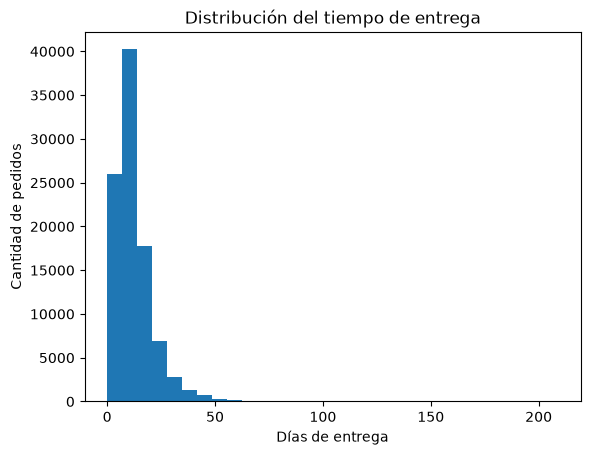

In [12]:
plt.hist(orders["dias_entrega"].dropna(), bins=30)
plt.xlabel("Días de entrega")
plt.ylabel("Cantidad de pedidos")
plt.title("Distribución del tiempo de entrega")
plt.show()

In [6]:
print((orders["dias_entrega"] > 60).sum())
print((orders["dias_entrega"] > 100).sum())
print((orders["dias_entrega"] > 150).sum())

288
63
24


In [7]:
print((orders["dias_entrega"] > 60).sum() / orders["dias_entrega"].notna().sum())

0.002985198391309756


En los datos y en el gráfico se puede apreciar que la mitad de los pedidos tarda 10 días o menos y el 75% llega para los 15 días, los demás llegan a los 60 días o menos. Sin embargo, hay una minoría, 0,3%, que llega luego de los 60 días, son un total de 288 de los 96.476 pedidos con fecha de entrega. De estos 288, 63 superaron los 100 días y 24 los 150. Los datos no revelan por qué estos pedidos llegan tan tarde, considerando su cantidad, una hipótesis es que se trata de pedidos en zonas lejanas del país o pedidos que se extravían y se vuelven a recuperar.

En los datos y en el gráfico se puede apreciar que la mitad de los pedidos tarda 10 días o menos y el 75% llega en 15 días o menos; los demás llegan en 60 días o menos. Sin embargo, hay una minoría (0,3%) que llega luego de los 60 días: son 288 de los 96.476 pedidos con fecha de entrega. De estos 288, 63 superaron los 100 días y 24 los 150. Los datos no revelan por qué estos pedidos llegan tan tarde; una hipótesis es que se trate de pedidos a zonas lejanas del país o de pedidos que se extravían y se recuperan, pero habría que comprobarlo.